# plot the temporal development of annual means vs. annual mean T
- input: slope data (from nbook 71_xx) & annual data from nbook 70_xx
- output:
    - plot annual means with error bars (percentile-based from bootstrap annual means)

In [1]:
import sys
import os
import pandas as pd

from pathlib import Path
import pickle

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import sys 
sys.path.append("../tools")
import plots_figures as plots_figs
from defs_application import * 
import defs_application
import cell_props


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# set output
output_directory = Path(f"../output/plots/dev")
output_directory.mkdir(parents=True, exist_ok=True)

input_dir =  Path("../output/annual/data")

datasets = ["cell_tracks","cell_features","anvil_features","domain"]


# 1. import data
# 1.1. annual data

In [3]:
yearly_stats = {}
for dataset in datasets:
    input_path = os.path.join(input_dir, f"yearly_stats_abso_boot_{dataset}.pkl")
    with open(input_path, "rb") as f:
        yearly_stats[dataset]= pickle.load(f)

## 1.2 SLOPES

In [4]:
slopes = {}
all_slopes = {}
all_intercepts = {}
for dataset in datasets:
    # dir with paths
    csv_info= {
        'ALL': f"../output/annual/data_slopes/df_lm_coefficients_boot_{dataset}_rel_T_CIspace.csv",
        }
    slopes[dataset]= cell_props.read_slopes_csv_as_ds(csv_info)

    ## all slopes
    inputpath = f"../output/annual/data_slopes/df_lm_slopes_all_boot_{dataset}_rel_T_CI_space.csv"
    all_slopes[dataset]=pd.read_csv(inputpath,index_col=0)

    # all intercepts
    inputpath=  f"../output/annual/data_slopes/df_lm_intercepts_all_boot_{dataset}_rel_T_CI_space.csv"
    # read and convert to xarray dataset
    all_intercepts[dataset]= pd.read_csv(inputpath,index_col=0)

# drop feature columns (except PE_anvil_feature_mean)
for name, dset in slopes.items():
    slopes[name] = dset.drop_sel(
        variable=[v for v in dset.variable.values 
                  if "feature" in v.lower() and v != "PE_anvil_feature_mean"]
    )

for name, df in all_slopes.items():
    all_slopes[name] = df.drop(
        columns=[c for c in df.columns 
                 if "feature" in c.lower() and c != "PE_anvil_feature_mean"]
    )

for name, df in all_intercepts.items():
    all_intercepts[name] = df.drop(
        columns=[c for c in df.columns 
                 if "feature" in c.lower() and c != "PE_anvil_feature_mean"]
    )

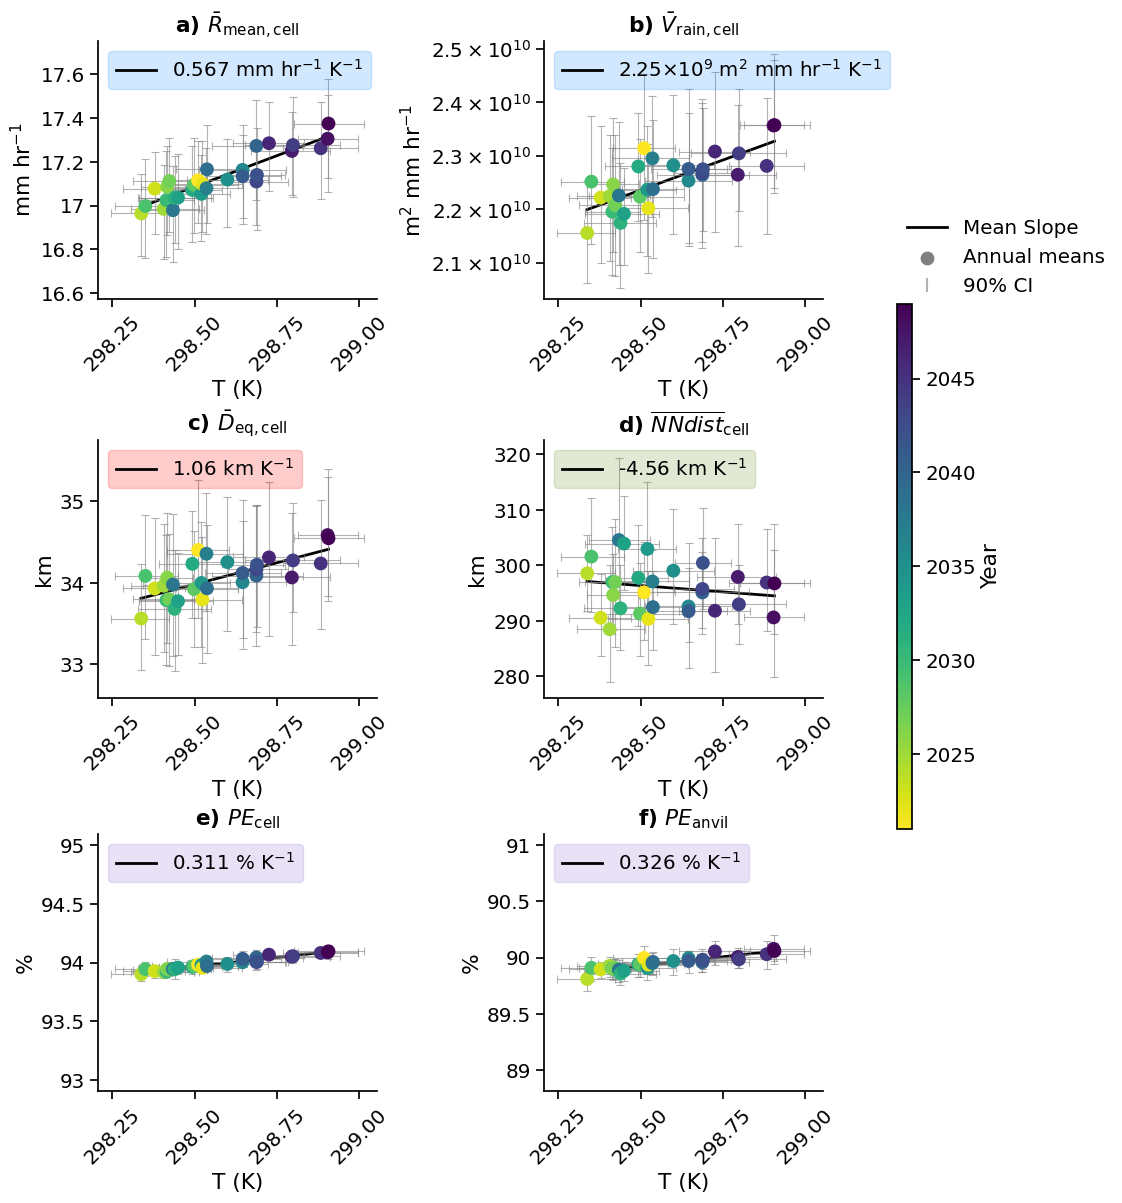

In [12]:
# select data
dataset = "cell_tracks"
annual_stats = yearly_stats[dataset]
source = "ICON"   


# beauty stuff selection
variables_to_plot = [ 
'mean_precip_cell_mean',
    #'max_precip_cell_max', 
    'rain_volume_cell_mean',
    'd_eq_cell_mean',
    'min_dist_cell_km_mean',
    #'velo_cell_mean','lifetime_cell',
    "PE_cell","PE_anvil"
]

VAR_META = defs_application.make_var_meta(variables_to_plot, source=source)

temp_var = [c for c in annual_stats["mean"].variables if "tas" in c.lower()][0]


plots_figs.plot_yearly_dev_abs_sorted_by_t_multi(
    data=annual_stats["mean"],
    variables=variables_to_plot, # if more variables are passed here the get plotted in the same plot!
    var_meta=VAR_META,
    variable_name_of_temperature_data=temp_var,
    x_label="T (K)",
    #title= "Cells and Precipitation Efficiency",
    ###  with error bars 
    data_low=annual_stats["ci_low"],
    data_upper=annual_stats["ci_high"],
    ncols = 2,


    #### for slopes
    slopes = slopes[dataset],

    
    ### for saving
    save=True,
    output_directory=output_directory,
    output_file = f"scatter_annualmeans_slope.pdf",
    
    legendright= True,
    fontscale = 1.3
)

# all plots

In [6]:
# set output
output_directory = Path(f"../../output/annual/plots")
output_directory.mkdir(parents=True, exist_ok=True)

input_dir =  Path("../output/annual/data")

datasets = ["cell_tracks","cell_features","anvil_features","domain"]

var_order_tracks = defs_application.var_order_tracks_cellonly
var_order_cell_features= defs_application.var_order_cell_features
var_order_anvil_features= defs_application.var_order_anvil_features
var_order_domain = defs_application.var_order_domain


var_order_anvil_features = ['mean_precip_anvil',
 'rain_volume_anvil',
 'convective_rain_volume_anvil',
 'fraction_convection_rain_volume_anvil',
                             'min_tb_anvil',
                             'mean_iwp_anvil', 'd_eq_anvil',
 'min_dist_anvil_km',
 'n_children_anvil',
]

                            
var_order_tracks = [ 
'mean_precip_cell_mean',
    #'max_precip_cell_max', 
    'rain_volume_cell_mean',
    'd_eq_cell_mean',
    'min_dist_cell_km_mean',
    #'velo_cell_mean','lifetime_cell',
    "PE_cell","PE_anvil"
]

var_order_cell_features = ['mean_precip_cell',
                 'max_precip_cell',
                 'rain_volume_cell',
                 'd_eq_cell',
                 'min_dist_cell_km',
                          ]



In [7]:
variable_order_map = {
    "cell_tracks":    var_order_tracks,
    "cell_features":  var_order_cell_features,
    "anvil_features": var_order_anvil_features,
    "domain":var_order_domain
}

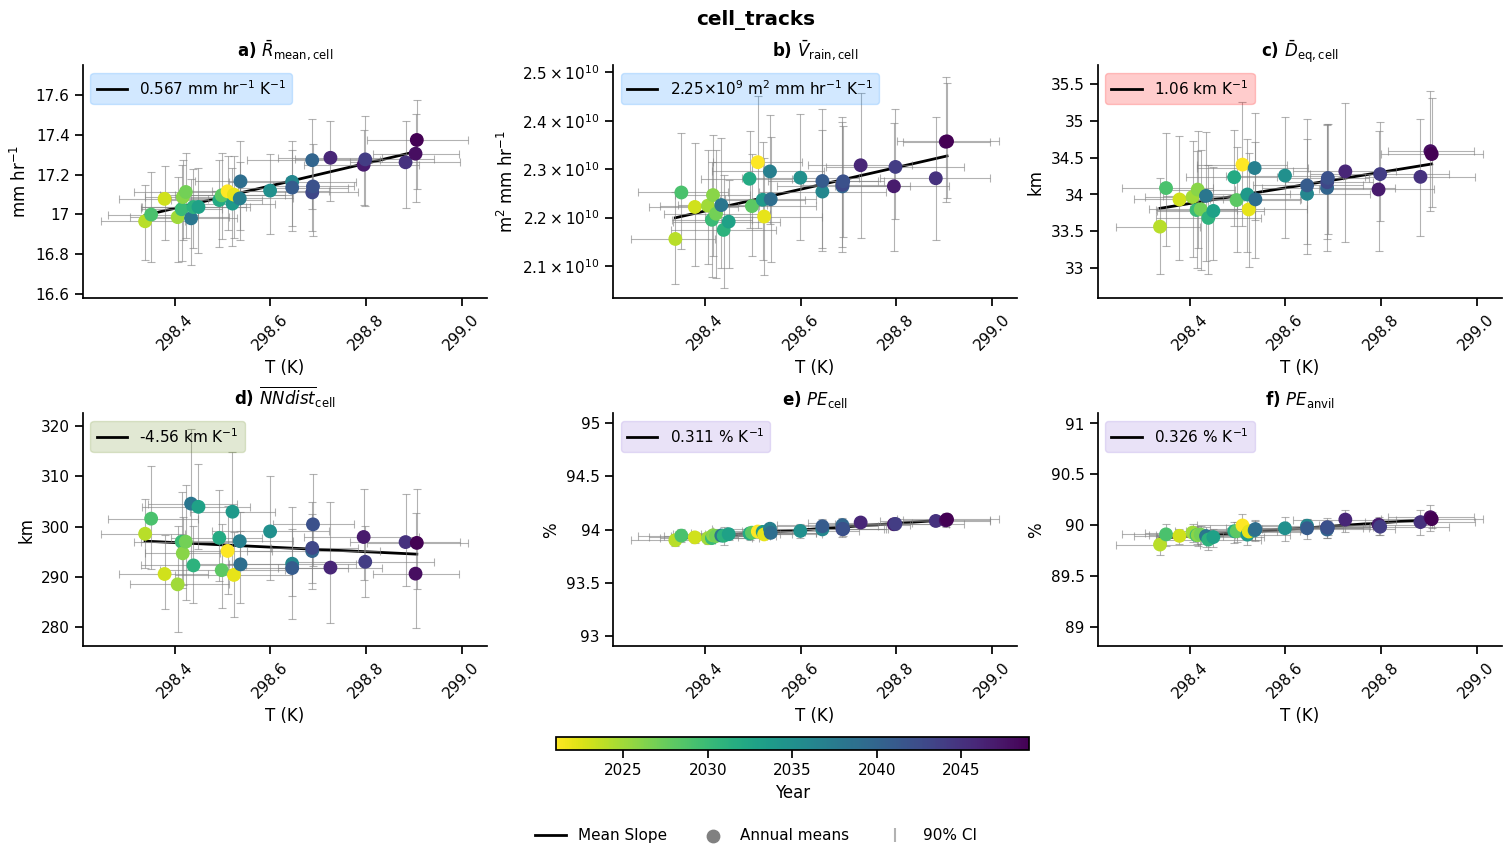

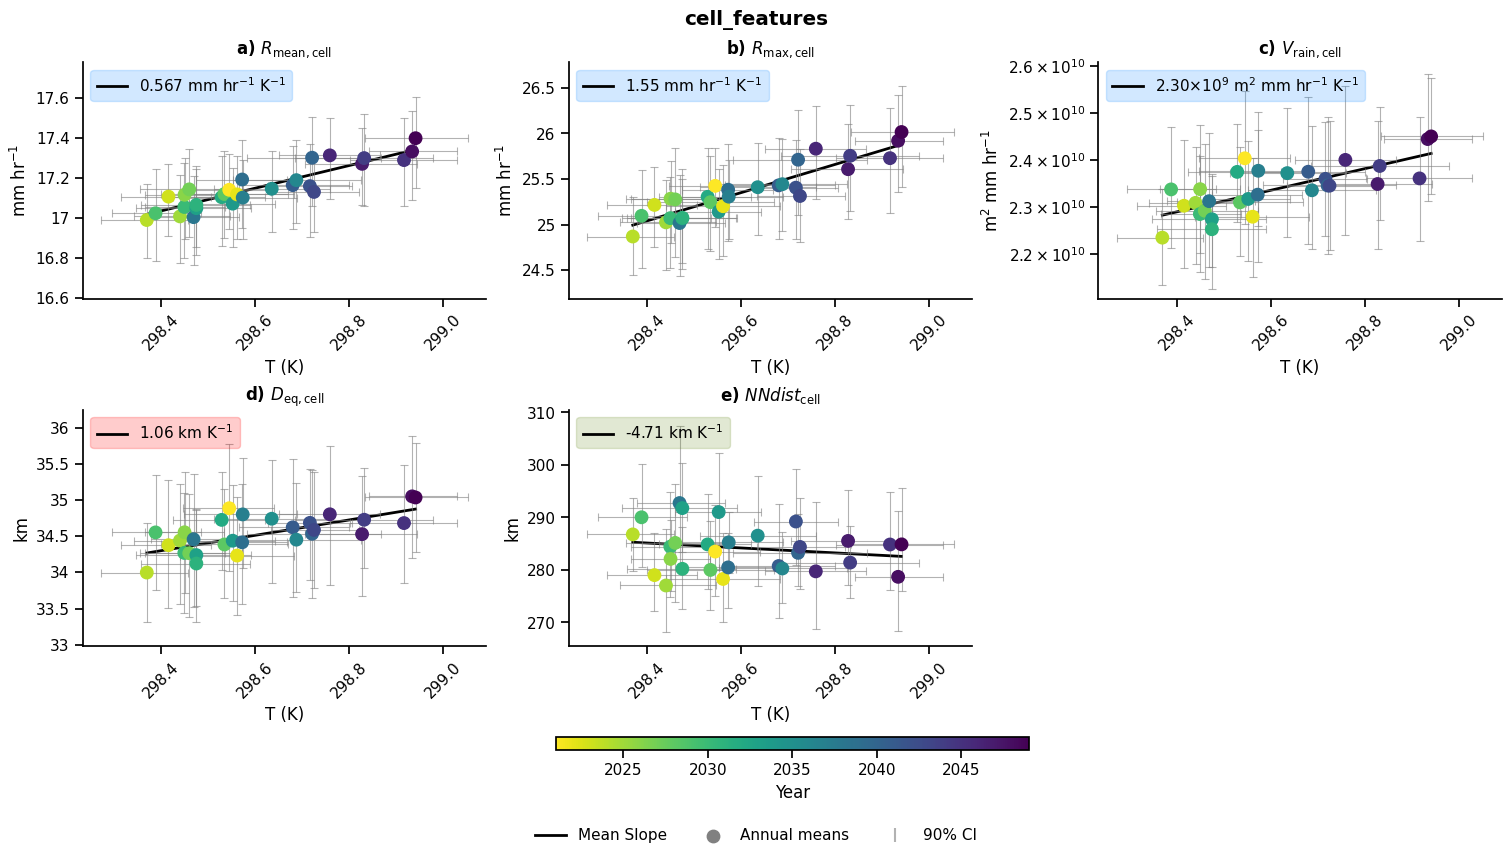

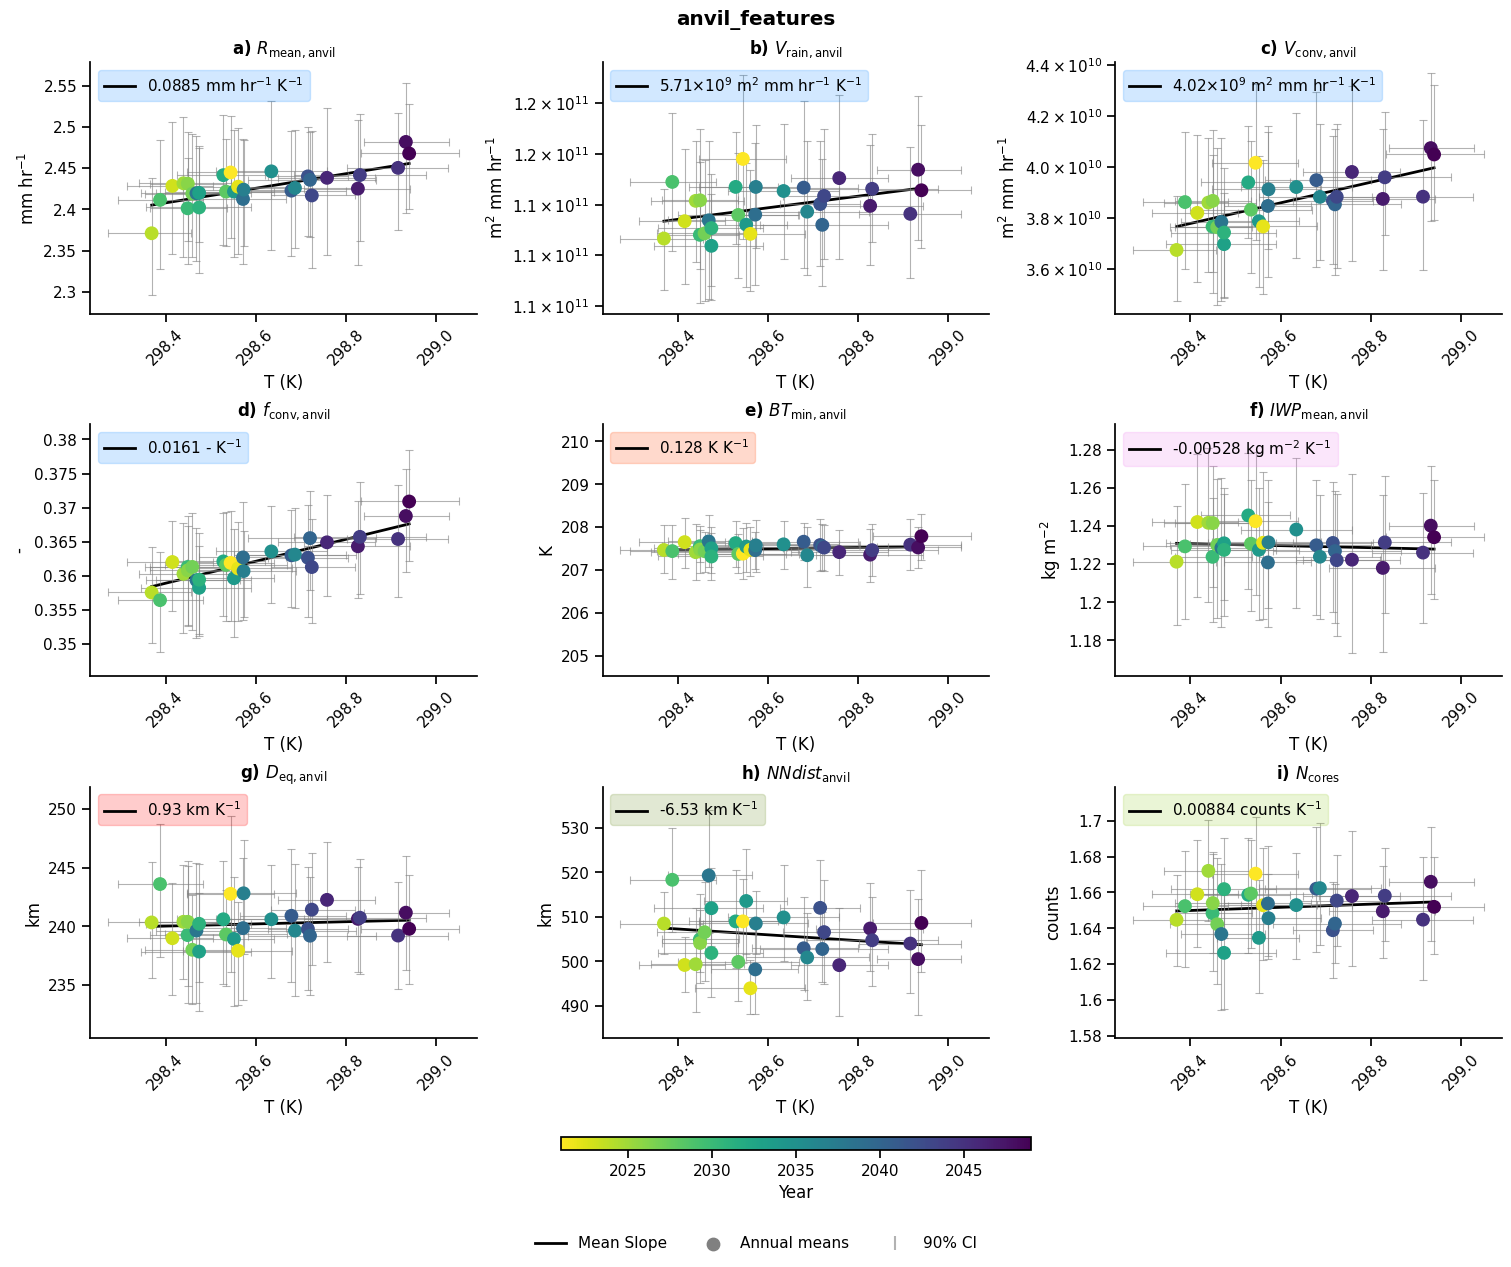

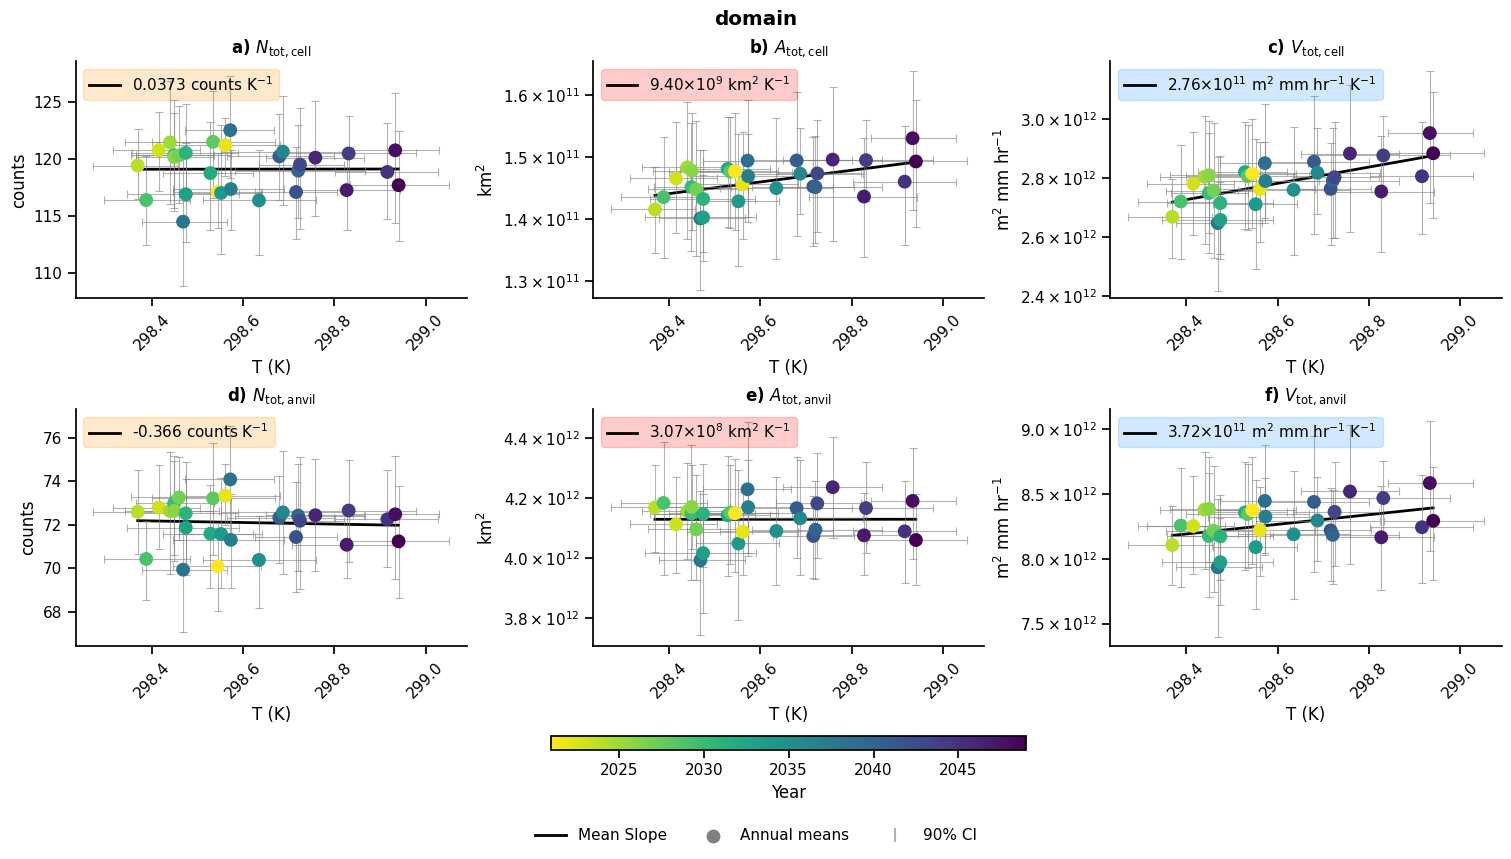

In [8]:
yearly_stats = yearly_stats
slopes = slopes
#datasets = ["cell_tracks"]

for dataset in datasets: 
    # select data
    annual_stats = yearly_stats[dataset]


    # beauty stuff selection
    variables_to_plot = variable_order_map[dataset] #list(dsplot.variable.values)

    source = "ICON"   
    VAR_META = defs_application.make_var_meta(variables_to_plot, source=source)

    temp_var = [c for c in annual_stats["mean"].variables if "tas" in c.lower()][0]


    plots_figs.plot_yearly_dev_abs_sorted_by_t_multi(
        data=annual_stats["mean"],
        variables=variables_to_plot, # if more variables are passed here the get plotted in the same plot!
        var_meta=VAR_META,
        variable_name_of_temperature_data=temp_var,
        x_label="T (K)",
        title=f"{dataset.lower()}",
        ###  with error bars 
        data_low=annual_stats["ci_low"],
        data_upper=annual_stats["ci_high"],
       # ncols = 2,

        #### for slopes
        slopes = slopes[dataset],
    )

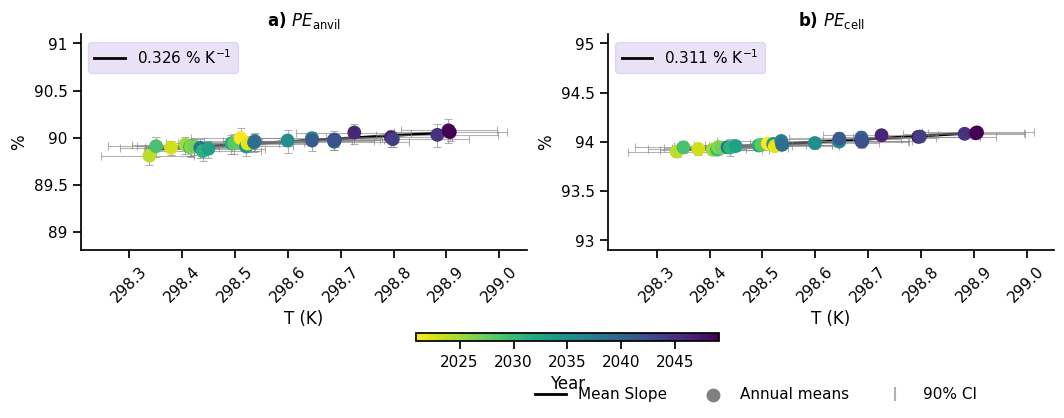

In [9]:
yearly_stats = yearly_stats
slopes = slopes


for dataset in ["cell_tracks"]: 
    # select data
    annual_stats = yearly_stats[dataset]


    # beauty stuff selection
    variables_to_plot = ["PE_anvil","PE_cell"]#list(dsplot.variable.values)

    source = "ICON"   
    VAR_META = defs_application.make_var_meta(variables_to_plot, source=source)

    temp_var = [c for c in annual_stats["mean"].variables if "tas" in c.lower()][0]


    plots_figs.plot_yearly_dev_abs_sorted_by_t_multi(
        data=annual_stats["mean"],
        variables=variables_to_plot, # if more variables are passed here the get plotted in the same plot!
        var_meta=VAR_META,
        variable_name_of_temperature_data=temp_var,
        x_label="T (K)",
        title=None ,#f"{dataset.lower()}",
        ###  with error bars 
        data_low=annual_stats["ci_low"],
        data_upper=annual_stats["ci_high"],

        #### for slopes
        slopes = slopes[dataset],

        # # for all slopes
        # plot_ci_slopes = True,
        # all_slopes = all_slopes[dataset],
        # all_intercepts= all_intercepts[dataset],
        
        ### for saving
        # save=True,
        # output_directory=output_directory,
        # output_file = f"yearly_evolution_sorted_tas_{experiment}_global_abs_change{var}_with_errorbars.png",
    )